# Random Forest — CNC Machine Health

**Dataset:** `cnc_machine_health.csv`

Six CNC machines. Five sensors each. One question:
> **Can we detect machine faults automatically from sensor readings?**

| Column | Sensor | Unit |
|---|---|---|
| `vibration` | Spindle vibration | m/s² |
| `temperature` | Cutting temperature | °C |
| `current` | Motor current draw | Amperes |
| `coolant_flow` | Coolant flow rate | L/min |
| `spindle_rpm` | Spindle speed | RPM |
| `fault_type` | **Target** — 0=Normal, 1=Bearing wear, 2=Tool wear, 3=Overheating |

---

## 1 — Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

plt.rcParams['figure.figsize'] = (10, 4)

print('Libraries loaded.')

Libraries loaded.


## 2 — Load and Understand the Data

Before training anything, we read the data and check it makes sense.
Three questions to answer every time:
- How many rows and columns?
- Are there missing values?
- Is the target balanced?

In [3]:
df = pd.read_csv('cnc_machine_health.csv')

print('Shape:', df.shape)
print()
print('First 5 rows:')
df.head()

Shape: (2592, 8)

First 5 rows:


,timestamp,machine_id,vibration,temperature,current,coolant_flow,spindle_rpm,fault_type
0,2024-01-01 00:00:00,M1,0.3597,55.69,8.494,NaN,2998.4,0
1,2024-01-01 00:10:00,M1,0.3089,58.65,8.606,11.568,3071.9,0
2,2024-01-01 00:20:00,M1,0.3718,61.01,8.943,12.014,NaN,0
3,2024-01-01 00:30:00,M1,0.4418,56.72,8.967,12.057,2962.5,0
4,2024-01-01 00:40:00,M1,0.3013,61.39,9.129,11.266,2979.0,0


Missing values per column:
timestamp        0
machine_id       0
vibration       72
temperature     72
current         72
coolant_flow    72
spindle_rpm     72
fault_type       0
dtype: int64

Fault type counts:
fault_type
0    2404
1      52
2      57
3      79
Name: count, dtype: int64


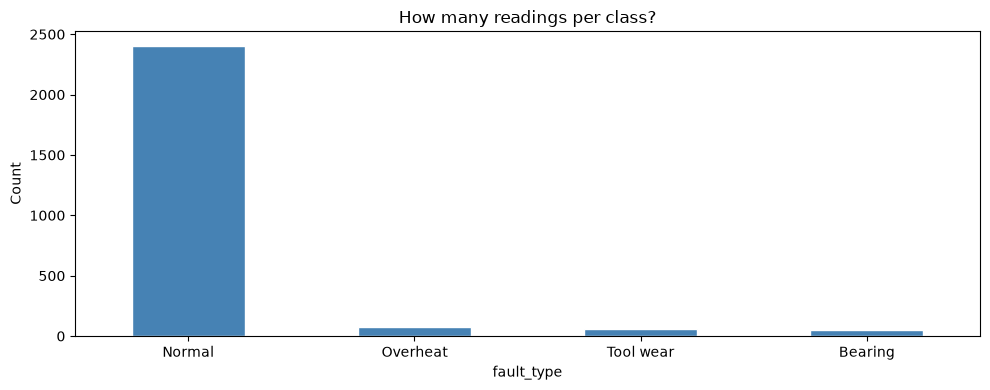

Fault rate: 0.073


In [4]:
# Missing values
print('Missing values per column:')
print(df.isnull().sum())

# Target distribution
print()
print('Fault type counts:')
print(df['fault_type'].value_counts().sort_index())

labels = {0:'Normal', 1:'Bearing', 2:'Tool wear', 3:'Overheat'}
df['fault_type'].map(labels).value_counts().plot(
    kind='bar', color='steelblue', edgecolor='white', rot=0)
plt.title('How many readings per class?')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

print('Fault rate:', round((df['fault_type'] > 0).mean(), 3))

## 3 — Explore: Do Sensors Look Different During Faults?

If the sensor values are different during faults, the model can learn to spot them.
We visualise this before building anything.

In [ ]:
SENSORS = ['vibration', 'temperature', 'current', 'coolant_flow', 'spindle_rpm']
COLORS  = {0:'steelblue', 1:'tomato', 2:'seagreen', 3:'darkorange'}
NAMES   = {0:'Normal', 1:'Bearing', 2:'Tool wear', 3:'Overheat'}

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, sensor in zip(axes, SENSORS):
    for ftype in sorted(df['fault_type'].unique()):
        vals = df[df['fault_type'] == ftype][sensor].dropna()
        ax.hist(vals, bins=25, alpha=0.5, color=COLORS[ftype], label=NAMES[ftype])
    ax.set_title(sensor)
    ax.set_xlabel('Value')

handles = [plt.Rectangle((0,0),1,1, color=COLORS[k]) for k in COLORS]
fig.legend(handles, NAMES.values(), loc='upper right', fontsize=9)
plt.suptitle('Sensor distributions by fault type', fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('Which sensor looks most different between Normal and Fault?')
print('That sensor will likely score high in feature importance.')

## 4 — Prepare the Data

Three steps before training:
1. Fill missing values with the column median
2. Separate features (X) from the target (y)
3. Split into train and test sets

> **Why stratify?** The fault classes are rare (~7%). Without stratify,
> the test set might have almost no faults to evaluate against.

In [ ]:
# Fill missing values
df[SENSORS] = df[SENSORS].fillna(df[SENSORS].median())
print('Missing values remaining:', df[SENSORS].isnull().sum().sum())

# Features and target
X = df[SENSORS]
y = df['fault_type']

# Train / test split — 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f'Training samples: {len(X_train)}')
print(f'Test samples:     {len(X_test)}')

## 5 — What Is a Random Forest?

A single decision tree asks yes/no questions about sensor values to reach a prediction.
The problem: one tree is fragile. Small changes in the data produce a very different tree.

A **Random Forest** fixes this by building many trees and combining their votes.

```
Training data
     |
     ├── Random sample → Tree 1 → Predicts: Bearing wear
     ├── Random sample → Tree 2 → Predicts: Bearing wear
     └── Random sample → Tree 3 → Predicts: Normal
                              ↓
                     Majority vote → Bearing wear
```

Two sources of randomness make each tree different:
- Each tree sees a **different random sample** of the training rows
- Each split considers only a **random subset of features**

Different errors cancel out. The forest is stronger than any single tree.

## 6 — Train the Model

In [ ]:
model = RandomForestClassifier(
    n_estimators=100,       # number of trees
    class_weight='balanced',# compensate for rare fault classes
    random_state=42
)

model.fit(X_train, y_train)

print('Model trained on', len(X_train), 'samples using', model.n_estimators, 'trees.')

## 7 — Evaluate: How Well Does It Work?

We test on data the model has **never seen**.

Key metrics for fault detection:
- **Precision** — when the model says 'fault', how often is it right?
- **Recall** — of all real faults, how many did the model catch?
- **F1** — the balance between the two

> For safety systems, **recall matters most**. A missed fault is more dangerous than a false alarm.

In [ ]:
y_pred = model.predict(X_test)

print(f'Overall accuracy: {model.score(X_test, y_test):.3f}')
print()
print(classification_report(
    y_test, y_pred,
    target_names=['Normal','Bearing','Tool wear','Overheat']
))

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
labels = ['Normal','Bearing','Tool wear','Overheat']

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(
    cmap='Blues', ax=ax, colorbar=False)
plt.title('Confusion Matrix\n(rows = actual, columns = predicted)',
          fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

print('Diagonal = correct predictions.')
print('Off-diagonal = mistakes — which fault types get confused?')

## 8 — Feature Importance: Which Sensor Matters Most?

Every time a feature is used to split a node in any tree, the model tracks
how much that split reduced prediction error. The total across all trees
gives each feature an importance score (they sum to 1).

**High score = the model relied on this sensor to make correct predictions.**

This directly answers: *which sensors are worth the hardware cost?*

In [ ]:
importances = pd.Series(
    model.feature_importances_,
    index=SENSORS
).sort_values()

colors = ['tomato' if v >= importances.median() else 'steelblue'
          for v in importances.values]

plt.figure(figsize=(8, 4))
plt.barh(importances.index, importances.values,
         color=colors, edgecolor='white')
plt.axvline(importances.median(), color='black',
            linestyle='--', linewidth=1, label='Median')
plt.xlabel('Importance score')
plt.title('Feature Importance — Which sensor drives fault detection?',
          fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

print('Top sensor:', importances.idxmax())
print('Score:     ', importances.max().round(4))
print()
print('Does this match what you saw in the histograms in Section 3?')

## 9 — How Many Trees Do You Need?

More trees = more stable predictions. But there is a point of diminishing returns —
going from 100 to 500 trees rarely improves accuracy much.

Run the cell and find the elbow in the curve.

In [ ]:
tree_counts = [1, 5, 10, 25, 50, 100, 200]
scores = []

for n in tree_counts:
    m = RandomForestClassifier(
        n_estimators=n,
        class_weight='balanced',
        random_state=42
    )
    m.fit(X_train, y_train)
    scores.append(m.score(X_test, y_test))

plt.figure(figsize=(9, 4))
plt.plot(tree_counts, scores, 'o-', color='steelblue', linewidth=2)
plt.xlabel('Number of trees (n_estimators)')
plt.ylabel('Test accuracy')
plt.title('More trees → more stable, but diminishing returns', fontweight='bold')
plt.tight_layout()
plt.show()

print('At how many trees does accuracy stop improving meaningfully?')

## 10 — Predict a Single Machine Reading

Let's make the model feel real.
We take one row from the test set, show the sensor values, and ask the model what it thinks.

In [ ]:
# Take the first test row
sample        = X_test.iloc[[0]]
true_label    = y_test.iloc[0]
predicted     = model.predict(sample)[0]
probabilities = model.predict_proba(sample)[0]

print('Sensor readings:')
print(sample.round(3).to_string(index=False))
print()
print(f'True fault type:      {NAMES[true_label]}')
print(f'Model predicted:      {NAMES[predicted]}')
print(f'Correct:              {true_label == predicted}')
print()
print('Model confidence per class:')
for i, prob in enumerate(probabilities):
    bar = '█' * int(prob * 30)
    print(f'  {NAMES[i]:<12}: {bar} {prob:.2%}')

## 11 — Try These Yourself

**Experiment A — Remove class_weight**
Go to Section 6. Remove `class_weight='balanced'`. Re-run Sections 6 and 7.
Look at the recall for Bearing, Tool wear, and Overheat.
Why does recall drop for the fault classes?

**Experiment B — Change n_estimators**
Go to Section 6. Change `n_estimators` to 5.
Re-run Sections 6 and 7. Does the confusion matrix get noisier?

**Experiment C — Remove your least important sensor**
Look at the feature importance chart in Section 8.
Remove the lowest-scoring sensor from the SENSORS list in Section 4.
Re-run Sections 4 through 8. How much does accuracy drop?
This answers: *can we save money by removing a sensor from the hardware?*

---

### What you practised

| Step | Skill |
|---|---|
| Load & explore | Reading a dataset, spotting class imbalance |
| Visualise | Histograms by class — do sensors separate faults? |
| Prepare | Missing values, train/test split, stratify |
| Train | RandomForestClassifier, class_weight |
| Evaluate | Accuracy, precision, recall, F1, confusion matrix |
| Interpret | Feature importance — which sensor matters most |
| Tune | n_estimators — how many trees are enough |
| Predict | Single-row inference with confidence scores |

---
*Random Forest Notebook — IoT ML Course*